# Superstore Sales: Exploratory Data Analysis

**CodeAlpha Data Analytics Internship, Task 2**

**Author:** Angela Iseriehen

---

## 1. Introduction

This notebook explores the Superstore Sales dataset to understand how sales are distributed across time, products, regions, and customer segments, and to detect data quality issues and anomalies.

### Questions I want to answer
1. How have sales chaged over time, and is there a seasonal pattern?
2. Which categories and sub-categories generate the most and the least sales?
3. Which regions, states and cities perform best?
4. Which customer segments and individual customers contribute the most?
5. Does delivery time differ by ship mode?
6. Are there outliers or anomalies in the sales values?

**Note:** This version of the dataset has no Profit, Quantity or Discount columns, so the analysis focuses on **sales**, not profitability.

## 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

pd.options.display.float_format = "{:,.2f}".format

## 3. Load and Inspect the Data

In [2]:
df = pd.read_csv("train.csv")

print("Shape:", df.shape)
df.head()

Shape: (9800, 18)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,"90,036.00",West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   float64
dtypes: float64(2), int6

### Column dictionary

| Column | Description | Type |
| --- | --- | --- |
| Row ID | Row number | Numeric (identifier) |
| Order ID | Unique order reference | Categorical |
| Order Date | Date the order was placed | Date (stored as text) |
| Ship Date | Date the order was shipped | Date (stored as text) |
| Ship Mode | Shipping method | Categorical |
| Customer ID / Customer Name | Customer identifiers | Categorical |
| Segment | Customer segment | Categorical |
| Country, City, State, Postal Code, Region | Location of the order | Categorical |
| Product ID, Product Name | Product identifiers | Categorical |
| Category, Sub-Category | Product grouping | Categorical |
| Sales | Sales amount of the line item | Numeric |

## 4. Data Quality Checks

In [4]:
# Missing values
missing = df.isnull().sum()
print("Missing values per column:")
print(missing[missing > 0])

# Duplicates
print("\nDuplicates:", df.duplicated().sum())
      
# Rwos with missing Postal Code
df[df['Postal Code'].isnull()][["Order ID", "City", "State", "Postal Code"]]

Missing values per column:
Postal Code    11
dtype: int64

Duplicates: 0


,Order ID,City,State,Postal Code
2234,CA-2018-104066,Burlington,Vermont,NaN
5274,CA-2016-162887,Burlington,Vermont,NaN
8798,US-2017-150140,Burlington,Vermont,NaN
9146,US-2017-165505,Burlington,Vermont,NaN
9147,US-2017-165505,Burlington,Vermont,NaN
9148,US-2017-165505,Burlington,Vermont,NaN
9386,US-2018-127292,Burlington,Vermont,NaN
9387,US-2018-127292,Burlington,Vermont,NaN
9388,US-2018-127292,Burlington,Vermont,NaN
9389,US-2018-127292,Burlington,Vermont,NaN


**Observation:** Postal Code has 11 missing values, and all of them belong to the same city and state (Burlington, Vermont). There are no duplicate rows.

## 5. Data Cleaning

Decisions made: 
1. **Postal Code:** all missingvalues are for one city (Burlington, vermont), so i filled them with that city's ZIP code (05401). Postal Code is also converted to text, because it is an identifier and not a number to calculate with.
2. **Dates:** converted from text to datetime. The format is day/month.year, so 'dayfirst=True' is required.
3. **New Columns:** 'Year','Month Name' and 'Delievery Days' (ship date minus order date).
4. **Dropped columns:** 'row ID' ( just a counter) and 'Country' (only one value, so no analytical value).

In [5]:
df_clean = df.copy()

# 1. Postal Code
df_clean["Postal Code"] = df_clean["Postal Code"].fillna(5401)
df_clean["Postal Code"] = df_clean["Postal Code"].astype(int).astype(str).str.zfill(5)

# 2. Dates
df_clean["Order Date"] = pd.to_datetime(df_clean["Order Date"], dayfirst=True)
df_clean["Ship Date"] = pd.to_datetime(df_clean["Ship Date"], dayfirst=True)

# 3. New columns
df_clean["Year"] = df_clean["Order Date"].dt.year
df_clean["Month"] = df_clean["Order Date"].dt.month
df_clean["Month Name"] = df_clean["Order Date"].dt.month_name()
df_clean["Delivery Days"] = (df_clean["Ship Date"] - df_clean["Order Date"]).dt.days

# 4. Drop columns with no analytical value
df_clean = df_clean.drop(columns=["Row ID", "Country"])

print("Missing values left:", df_clean.isna().sum().sum())
print("Date range:", df_clean["Order Date"].min().date(), "to", df_clean["Order Date"].max().date())
df_clean.head()

Missing values left: 0
Date range: 2015-01-03 to 2018-12-30


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Year,Month,Month Name,Delivery Days
0,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2017,11,November,3
1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,2017,11,November,3
2,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2017,6,June,4
3,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,2016,10,October,7
4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2016,10,October,7


## 6. Summary Statistics

In [6]:
df_clean[["Sales", "Delivery Days"]].describe()

,Sales,Delivery Days
count,"9,800.00","9,800.00"
mean,230.77,3.96
std,626.65,1.75
min,0.44,0.00
25%,17.25,3.00
50%,54.49,4.00
75%,210.61,5.00
max,"22,638.48",7.00


In [7]:
print("Mean sales:", round(df_clean["Sales"].mean(), 2))
print("Median sales:", round(df_clean["Sales"].median(), 2))
print("skewness:", round(df_clean["Sales"].skew(), 2))

Mean sales: 230.77
Median sales: 54.49
skewness: 12.98


In [8]:
for col in ["Segment", "Category", "Region", "Ship Mode"]:
    print(f"--{col} ---")
    print(df_clean[col].value_counts())
    print()

--Segment ---
Segment
Consumer       5101
Corporate      2953
Home Office    1746
Name: count, dtype: int64

--Category ---
Category
Office Supplies    5909
Furniture          2078
Technology         1813
Name: count, dtype: int64

--Region ---
Region
West       3140
East       2785
Central    2277
South      1598
Name: count, dtype: int64

--Ship Mode ---
Ship Mode
Standard Class    5859
Second Class      1902
First Class       1501
Same Day           538
Name: count, dtype: int64



**Observation:** The mean sales per order line (about 230.77) is far higher than the median (about 54.49), and the skewness is strongly positive (about 12.98). This means most orders are small, while a ew very large orders pull the average up. In terms of order lines, Consumer is the biggest segment (5,101 of 9,800, about 52%), office supplies is the biggest category (5,909, about 60%), West is the biggest region (3,140, about 32%) and Standard Class is the most used ship mode (5,859, about 60%).

## 7. Univariate Analysis

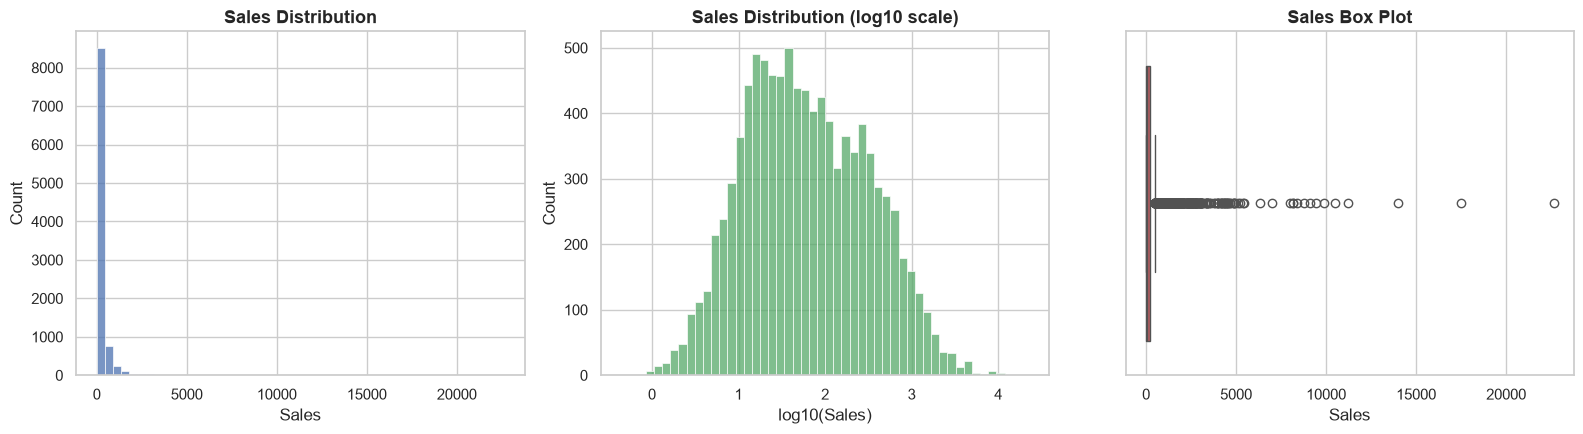

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(df_clean["Sales"], bins=50, ax=axes[0], color="#4C72B0")
axes[0].set_title("Sales Distribution")

sns.histplot(np.log10(df_clean["Sales"]), bins=50, ax=axes[1], color="#55A868")
axes[1].set_title("Sales Distribution (log10 scale)")
axes[1].set_xlabel("log10(Sales)")

sns.boxplot(x=df_clean["Sales"], ax=axes[2], color="#C44E52")
axes[2].set_title("Sales Box Plot")

plt.tight_layout()
plt.show()

**Finding:** Sales is heavily right-skewed. Most order lines are small, with the bulk below about 500, while a handful reach above 10,000, and the largest is over 22,000. On the log10 scale the distribution looks roughly bell-shaped, which shows that sales values are spread across orders of magnitude and that a log scale is the clearer way to view them. The box plot shows a large number of high-value outliers.

### 7.2 Categorical Variables

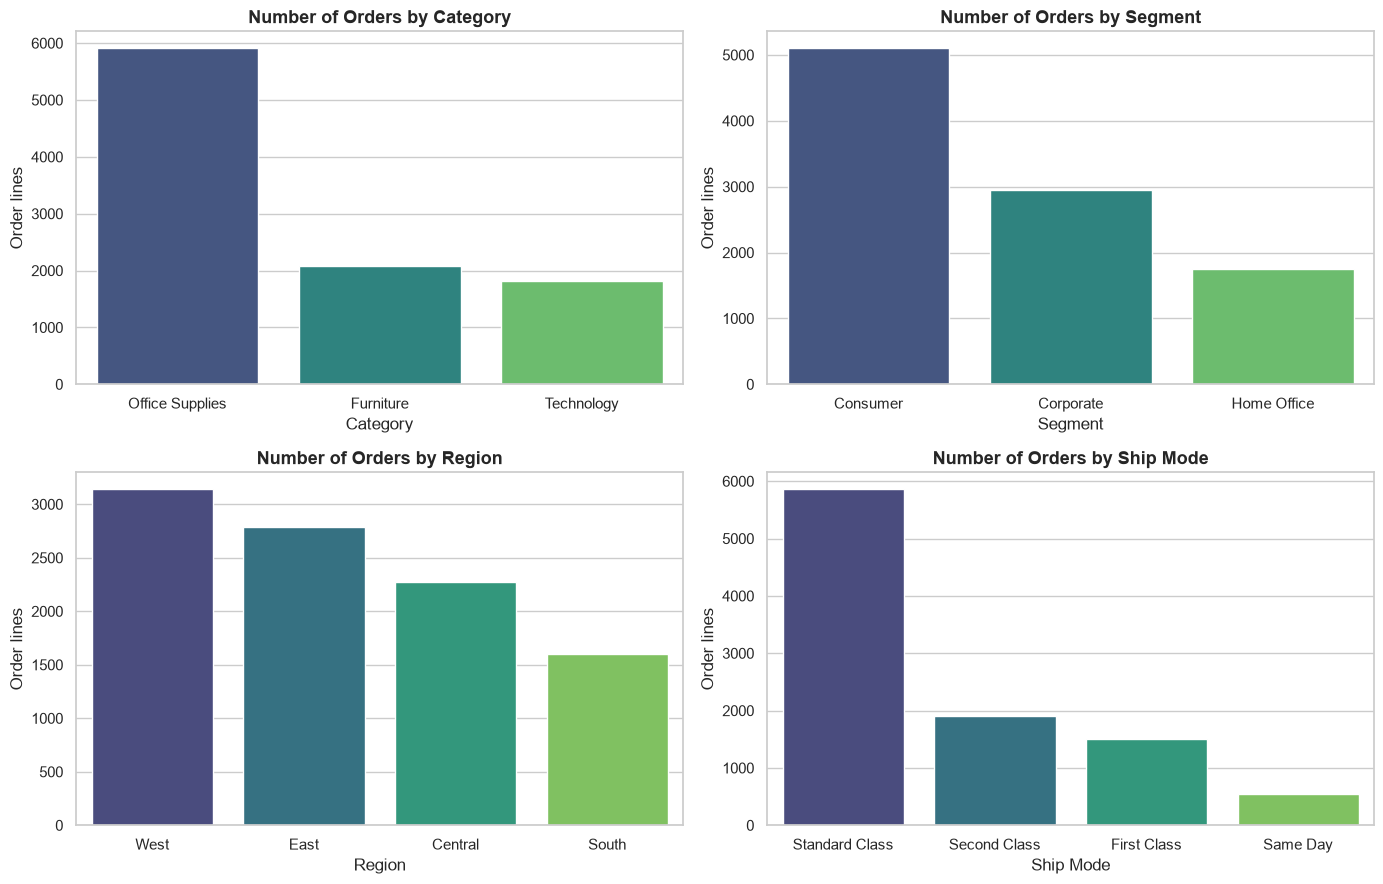

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, col in zip(axes.flatten(), ["Category", "Segment", "Region", "Ship Mode"]):
    order = df_clean[col].value_counts().index
    sns.countplot(data=df_clean, x=col, order=order, ax=ax, palette="viridis")
    ax.set_title(f"Number of Orders by {col}")
    ax.set_ylabel("Order lines")

plt.tight_layout()
plt.show()

**Finding:** Office Supplies has the most order lines (about 60%), well ahead of Furniture and Technology. Consumer is the largest segment, West is the largest region, and Standard Class is by far the most used ship mode. Same Day is used the least.

## 8. Answering the Questions

### Q1. How have sales changed over time?

Year
2015   479,856.21
2016   459,436.01
2017   600,192.55
2018   722,052.02
Name: Sales, dtype: float64


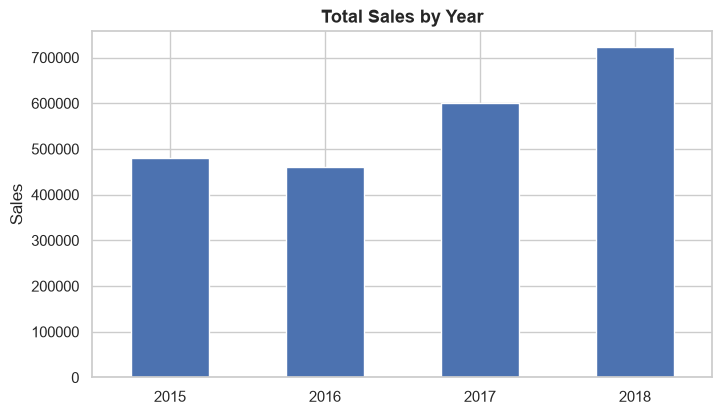

In [11]:
yearly = df_clean.groupby("Year")["Sales"].sum()
print(yearly.round(2))

ax = yearly.plot(kind="bar", color="#4C72B0", figsize=(8, 4.5))
ax.set_title("Total Sales by Year")
ax.set_ylabel("Sales")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.show()

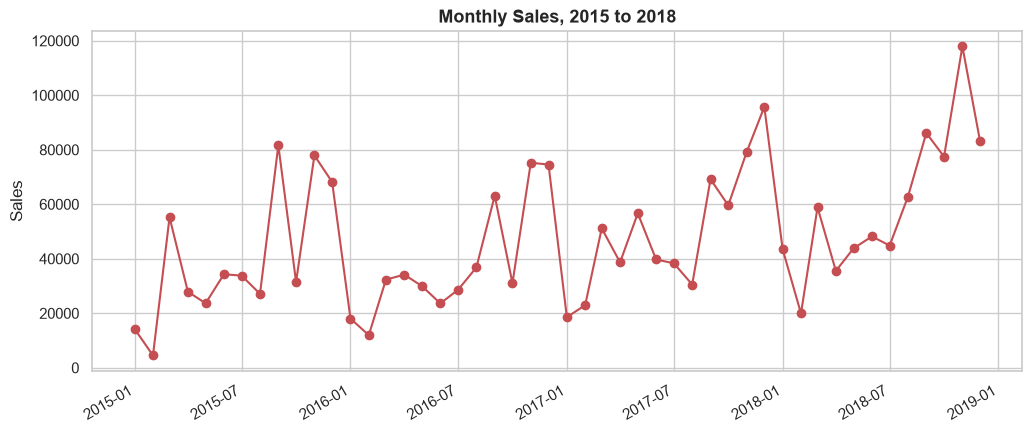

In [12]:
monthly = df_clean.groupby(df_clean["Order Date"].dt.to_period("M"))["Sales"].sum()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly.index, monthly.values, marker="o", color="#C44E52")
ax.set_title("Monthly Sales, 2015 to 2018")
ax.set_ylabel("Sales")
fig.autofmt_xdate()
plt.show()

### Is there a seasonal pattern?

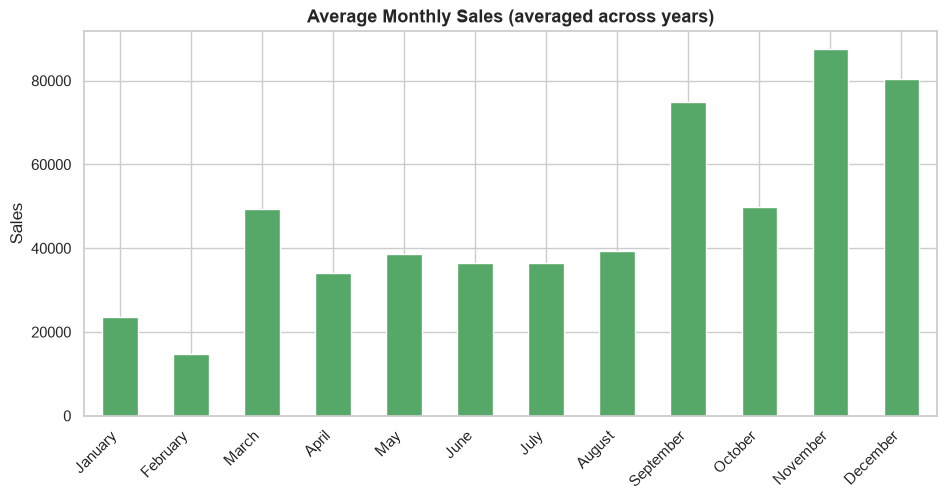

Strongest months: November, December, September
Weakest months:   February, January, April


In [13]:
month_order = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]

seasonal = (df_clean.groupby(["Year", "Month Name"])["Sales"].sum()
            .groupby("Month Name").mean().reindex(month_order))

ax = seasonal.plot(kind="bar", color="#55A868", figsize=(11, 5))
ax.set_title("Average Monthly Sales (averaged across years)")
ax.set_ylabel("Sales")
ax.set_xlabel("")
plt.xticks(rotation=45, ha="right")
plt.show()

print("Strongest months:", ", ".join(seasonal.sort_values(ascending=False).head(3).index))
print("Weakest months:  ", ", ".join(seasonal.sort_values().head(3).index))

**Finding:** Total sales dipped slightly from about 479,856 in 2015 to about 459,436 in 2016 (a drop of roughly 4%), then grew strongly to about 600,193 in 2017 (up about 31%) and about 722,052 in 2018 (up about 20%). Sales show a clear seasonal pattern. On average, November, December and September are the strongest months, while February, January and April are the weakest. The highest single month in the data is November 2018, at about 117,938. The late-year peak is likely linked to the holiday season and year-end purchasing, but the dataset does not confirm the reason.

### Q2. Which categories and sub-categories sell the most?

Category
Technology         36.6 %
Furniture          32.2 %
Office Supplies    31.2 %
Name: Sales, dtype: str


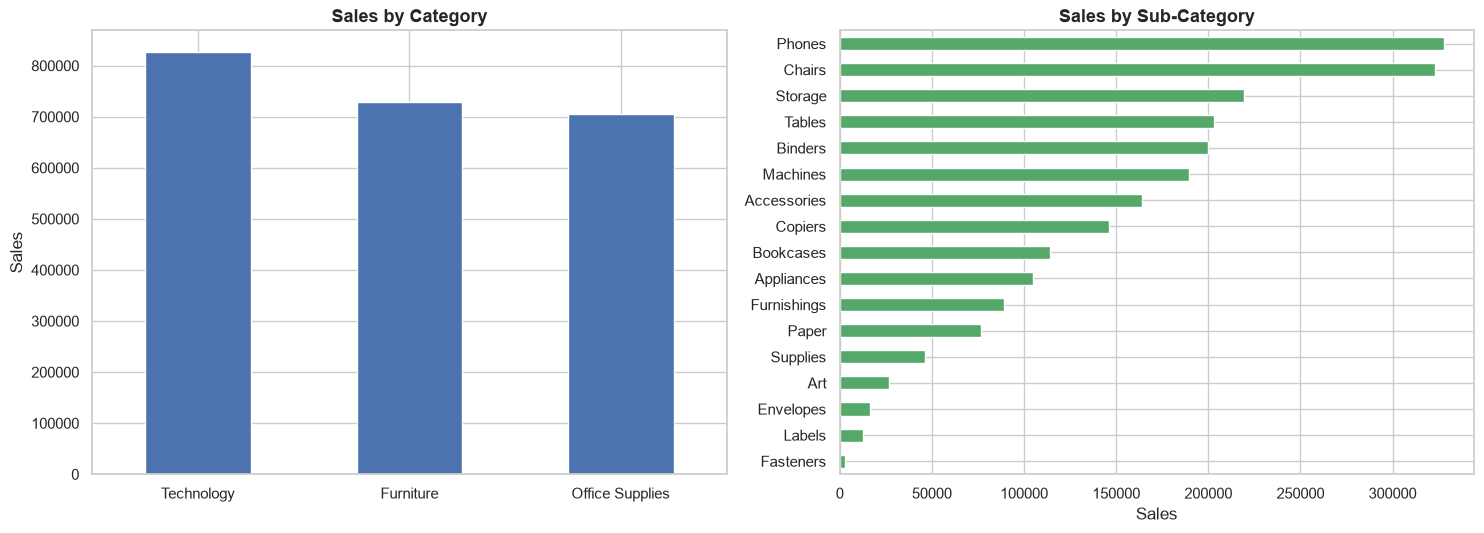

In [14]:
cat_sales = df_clean.groupby("Category")["Sales"].sum().sort_values(ascending=False)
print((cat_sales / cat_sales.sum() * 100).round(1).astype(str) + " %")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

cat_sales.plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Sales by Category")
axes[0].set_ylabel("Sales")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)

sub_sales = df_clean.groupby("Sub-Category")["Sales"].sum().sort_values()
sub_sales.plot(kind="barh", ax=axes[1], color="#55A868")
axes[1].set_title("Sales by Sub-Category")
axes[1].set_xlabel("Sales")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Finding:** Technology generates the most sales (about 36.6% of the total), followed by Furniture (32.2%) and Office Supplies (31.2%). This is the opposite of the order-line counts, where Office Supplies had about 60% of the rows. Office Supplies has many low-priced items, while Technology and Furniture have fewer but higher-value orders. At sub-category level, Phones (about 327,782) and Chairs (about 322,823) are the top sellers, followed by Storage, Tables and Binders. The weakest are Fasteners (about 3,002), Labels and Envelopes.

### Q3. Which regions, states and cities perform best?

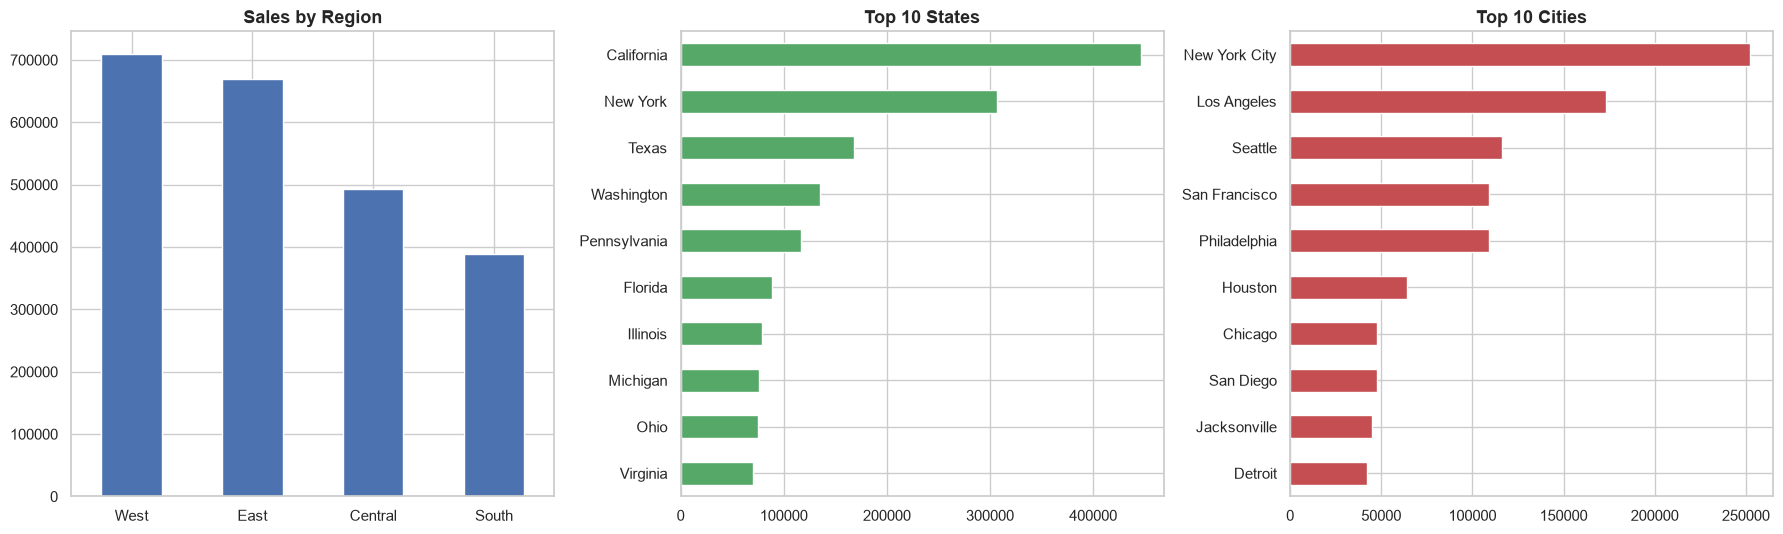

In [15]:
region_sales = df_clean.groupby("Region")["Sales"].sum().sort_values(ascending=False)
state_sales = df_clean.groupby("State")["Sales"].sum().sort_values(ascending=False).head(10)
city_sales = df_clean.groupby("City")["Sales"].sum().sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

region_sales.plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Sales by Region")
axes[0].tick_params(axis="x", rotation=0)
axes[0].set_xlabel("")

state_sales.sort_values().plot(kind="barh", ax=axes[1], color="#55A868")
axes[1].set_title("Top 10 States")
axes[1].set_ylabel("")

city_sales.sort_values().plot(kind="barh", ax=axes[2], color="#C44E52")
axes[2].set_title("Top 10 Cities")
axes[2].set_ylabel("")

plt.tight_layout()
plt.show()

**Finding:** The West is the top region (about 31.4% of sales), followed by the East (29.6%), Central (21.8%) and South (17.2%). California leads the states with about 446,306, followed by New York (about 306,361) and Texas (about 168,573). Together, the top three states account for roughly 41% of total sales. At city level, New York City (about 252,463) and Los Angeles (about 173,420) lead. Sales are heavily concentrated in a few large states and cities.

### Q4. Which segments and customers contribute the most?

Segment
Consumer       50.8 %
Corporate      30.4 %
Home Office    18.8 %
Name: Sales, dtype: str


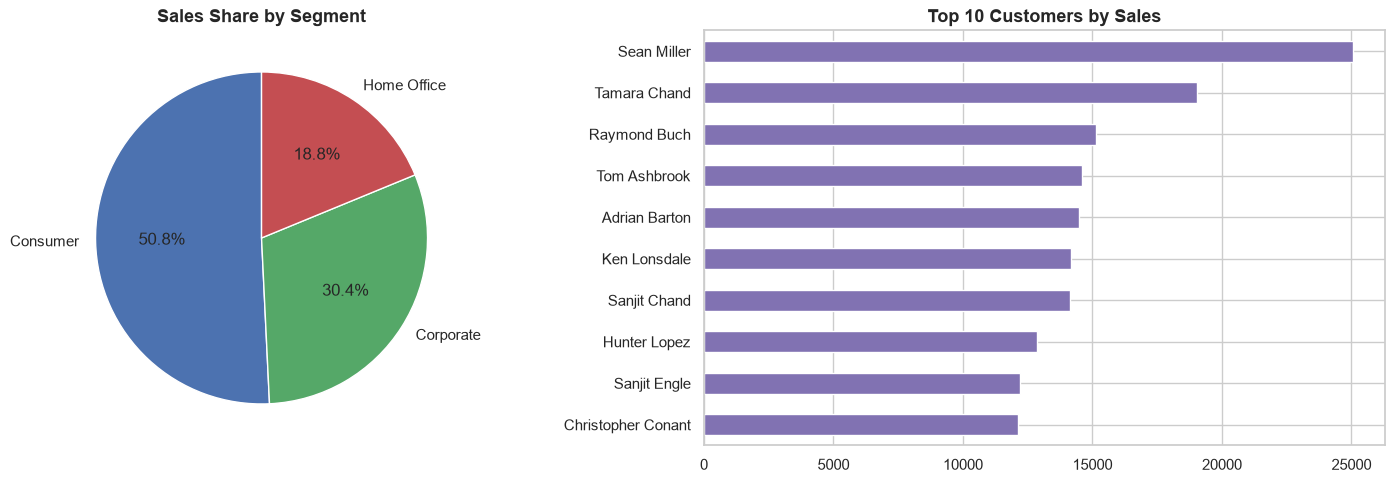

In [16]:
seg_sales = df_clean.groupby("Segment")["Sales"].sum().sort_values(ascending=False)
print((seg_sales / seg_sales.sum() * 100).round(1).astype(str) + " %")

top_customers = (df_clean.groupby("Customer Name")["Sales"].sum()
                 .sort_values(ascending=False).head(10))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].pie(seg_sales, labels=seg_sales.index, autopct="%1.1f%%", startangle=90,
            colors=["#4C72B0", "#55A868", "#C44E52"])
axes[0].set_title("Sales Share by Segment")

top_customers.sort_values().plot(kind="barh", ax=axes[1], color="#8172B2")
axes[1].set_title("Top 10 Customers by Sales")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Finding:** Consumer is the biggest segment, with about 50.8% of sales, followed by Corporate (30.4%) and Home Office (18.8%). Sales are not dependent on a few customers. The top customer, Sean Miller, spent about 25,043 and the next, Tamara Chand, about 19,052, but the top 10 customers together account for only about 6.8% of total sales across 793 customers. The customer base is broad, so losing any one customer would have a limited effect.

### Q5. Does delivery time differ by ship mode?

                mean  median  min  max
Ship Mode                             
Same Day        0.04    0.00    0    1
First Class     2.18    2.00    1    4
Second Class    3.25    3.00    1    5
Standard Class  5.01    5.00    3    7


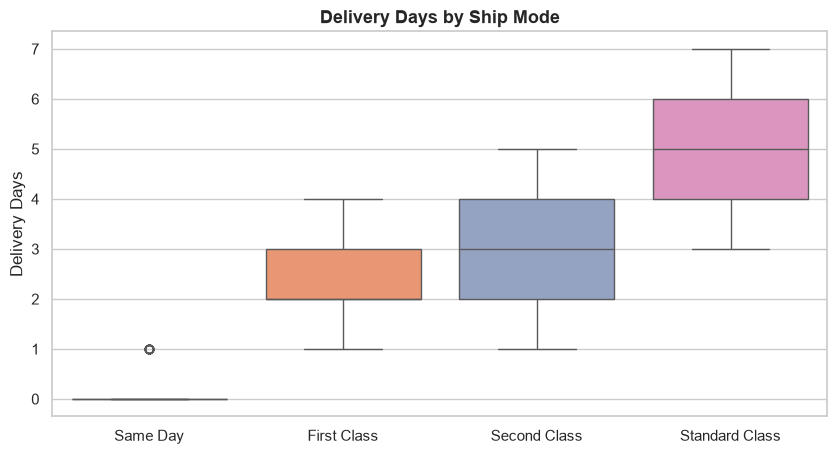

In [17]:
delivery = df_clean.groupby("Ship Mode")["Delivery Days"].agg(["mean", "median", "min", "max"]).round(2)
print(delivery.sort_values("mean"))

order = delivery.sort_values("mean").index
sns.boxplot(data=df_clean, x="Ship Mode", y="Delivery Days", order=order, palette="Set2")
plt.title("Delivery Days by Ship Mode")
plt.xlabel("")
plt.show()

**Finding:** Delivery time differs clearly by ship mode, and in the order you would expect. Same Day is fastest, at an average of about 0.04 days (almost always the same day). First Class averages about 2.2 days, Second Class about 3.3 days and Standard Class about 5 days, with a maximum of 7 days. Faster ship modes deliver faster as promised, and Standard Class is both the slowest and the most used.

## 9. Outlier Detection

In [18]:
Q1 = df_clean["Sales"].quantile(0.25)
Q3 = df_clean["Sales"].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR

outliers = df_clean[df_clean["Sales"] > upper]

print(f"Q1 = {Q1:.2f}, Q3 = {Q3:.2f}, IQR = {IQR:.2f}")
print(f"Upper fence = {upper:.2f}")
print(f"Outlier rows: {len(outliers)} ({len(outliers) / len(df_clean) * 100:.1f}% of all rows)")
print(f"Share of total sales from outliers: {outliers['Sales'].sum() / df_clean['Sales'].sum() * 100:.1f}%")

Q1 = 17.25, Q3 = 210.61, IQR = 193.36
Upper fence = 500.64
Outlier rows: 1145 (11.7% of all rows)
Share of total sales from outliers: 64.3%


In [19]:
df_clean.nlargest(10, "Sales")[["Order Date", "Customer Name", "Category", "Sub-Category", "Product Name", "Sales"]]

,Order Date,Customer Name,Category,Sub-Category,Product Name,Sales
2697,2015-03-18,Sean Miller,Technology,Machines,Cisco TelePresence System EX90 Videoconferenci...,"22,638.48"
6826,2017-10-02,Tamara Chand,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,"17,499.95"
8153,2018-03-23,Raymond Buch,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,"13,999.96"
2623,2018-10-22,Tom Ashbrook,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,"11,199.97"
4190,2018-11-17,Hunter Lopez,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,"10,499.97"
9039,2017-12-17,Adrian Barton,Office Supplies,Binders,GBC Ibimaster 500 Manual ProClick Binding System,"9,892.74"
4098,2015-09-23,Sanjit Chand,Office Supplies,Binders,Ibico EPK-21 Electric Binding System,"9,449.95"
4277,2017-04-16,Bill Shonely,Technology,Machines,"3D Systems Cube Printer, 2nd Generation, Magenta","9,099.93"
8488,2017-02-02,Sanjit Engle,Technology,Machines,HP Designjet T520 Inkjet Large Format Printer ...,"8,749.95"
6425,2017-05-23,Christopher Conant,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,"8,399.98"


**Finding:** Using the IQR method, any sales value above about 500.64 counts as an outlier. That is 1,145 order lines, about 11.7% of all rows, and they account for about 64.3% of total sales. The ten largest orders are all genuine high-value business equipment: copiers (the Canon imageCLASS 2200 appears several times), videoconferencing units, large-format printers and binding machines. The largest single line is a Cisco TelePresence System at about 22,638.

**Decision:** I kept the outliers. They look like real purchases of expensive equipment, not data entry errors, and removing them would remove most of the revenue. Because they skew the average, I use the median and non-parametric tests in the analysis instead.

## 10. Hypothesis Testing

Sales is heavily skewed, so I use **non-parametric tests** (Kruskal-Wallis) instead of ANOVA or t-tests, which assume roughly normal data. The significance level is 0.05.

### Test 1: Does sales per order line differ between customer segments?
- **H0:** The sales distributions are the same across segments.
- **H1:** At least one segment differs.

In [20]:
groups = [g["Sales"].values for _, g in df_clean.groupby("Segment")]
stat, p = stats.kruskal(*groups)

print(f"Kruskal-Wallis H = {stat:.3f}, p-value = {p:.4f}")
print("Result:", "Reject H0 (significant difference)" if p < 0.05 else "Fail to reject H0 (no significant difference)")
print()
print(df_clean.groupby("Segment")["Sales"].agg(["mean", "median"]).round(2))

Kruskal-Wallis H = 0.439, p-value = 0.8028
Result: Fail to reject H0 (no significant difference)

              mean  median
Segment                   
Consumer    225.07   53.98
Corporate   233.15   56.30
Home Office 243.40   52.56


### Test 2: Is delivery time different between ship modes?
- **H0:** Delivery days are the same across ship modes.
- **H1:** At least one ship mode differs.

In [21]:
groups = [g["Delivery Days"].values for _, g in df_clean.groupby("Ship Mode")]
stat, p = stats.kruskal(*groups)

print(f"Kruskal-Wallis H = {stat:.3f}, p-value = {p:.4g}")
print("Result:", "Reject H0 (significant difference)" if p < 0.05 else "Fail to reject H0 (no significant difference)")

Kruskal-Wallis H = 5937.818, p-value = 0
Result: Reject H0 (significant difference)


**Interpretation:**

- **Test 1 (segments):** The Kruskal-Wallis test gives H = 0.439 and p = 0.80, which is well above 0.05, so I fail to reject H0. There is no statistically significant difference in sales per order line between Consumer, Corporate and Home Office. The segments differ in how much they buy in total (Consumer is the biggest because it has the most order lines), but the typical size of an order line is similar across segments. The means look slightly different (about 225 to 243), but the test shows this gap is within normal variation, because a few very large orders affect the means.
- **Test 2 (ship modes):** The test gives H = 5937.8 and a p-value far below 0.001, so I reject H0. Delivery time differs significantly by ship mode. This confirms what the box plot showed: faster ship modes deliver faster, and the difference is not due to chance.

## 11. Conclusion

### Key insights
1. **Growth and seasonality:** Sales fell slightly in 2016 (about -4%), then grew about 31% in 2017 and about 20% in 2018, reaching about 722,000. November, December and September are the strongest months, while February, January and April are the weakest.
2. **Products:** Technology generates the most sales (about 36.6%) even though Office Supplies has the most order lines (about 60%). Phones and Chairs are the top sub-categories.
3. **Geography:** The West leads regionally (about 31.4%). California and New York are the top states, and the top three states account for about 41% of sales.
4. **Customers:** Consumer is the biggest segment (about 50.8% of sales). Sales are spread across 793 customers, and the top 10 account for only about 6.8%.
5. **Shipping:** Delivery time differs significantly by ship mode, from about 0 days (Same Day) to about 5 days (Standard Class), and most orders use the slowest mode.
6. **Outliers:** About 11.7% of order lines are outliers, but they make up about 64% of total sales. They are genuine high-value equipment purchases such as copiers and videoconferencing units.

### Recommendations
1. Prepare stock, staffing and promotions for September to December, and run campaigns in the slow months (January, February and April) to reduce the seasonal gap.
2. Prioritise Technology and Furniture, especially Phones and Chairs, because they drive the most sales, and review the weakest sub-categories (Fasteners, Labels and Envelopes).
3. Look at why the South has the lowest sales share and whether it is worth investing more there, while protecting the strong West and East regions.
4. Since a small number of large equipment orders drive most of the revenue, build relationships with the customers who buy them, and track them separately from everyday orders.

### Limitations
- The dataset has no profit, quantity or discount data, so profitability cannot be assessed. High sales does not always mean high profit.
- All orders are from one country (the United States), so the findings may not apply elsewhere.
- A small number of very large orders have a large influence on total sales.
- The reasons behind patterns, such as holiday-season peaks, are plausible explanations but are not confirmed by this dataset.

### Next steps
- Build an interactive dashboard from the cleaned data (Task 3).